<a href="https://colab.research.google.com/github/20deepak28/CHURNIQ--B2B-SaaS-Churn-Analytics/blob/main/04_machine_learning_model_development.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import pandas as pd
import numpy as np
import os

from sklearn.model_selection import train_test_split

In [4]:
project_path = '/content/drive/MyDrive/Customer-Lifetime-Value-Churn-Intelligence'

data_path = os.path.join(project_path, 'data')

file_path = os.path.join(
    data_path,
    'telco_churn_feature_engineered.csv'
)

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()

Dataset loaded successfully!
Shape: (7043, 22)


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,TenureGroup,AdditionalServicesCount
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,...,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,New,1
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,...,No,No,One year,No,Mailed check,56.95,1889.50,No,Established,2
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,...,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,New,2
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,...,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,Established,3
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,...,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,New,0


### Separate feature and target

In [5]:
X = df.drop(columns=['Churn'])
y = df['Churn'].map({'No': 0, 'Yes': 1})

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts(normalize=True) * 100)

Features shape: (7043, 21)
Target shape: (7043,)

Target distribution:
Churn
0    73.463013
1    26.536987
Name: proportion, dtype: float64


### train Test Split

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (5634, 21)
Testing data: (1409, 21)


### Identify numerical and categorical columns

In [7]:
numeric_features = X_train.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=['object', 'category']
).columns.tolist()

print("Numerical features:", numeric_features)
print("\nCategorical features:", categorical_features)

Numerical features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'AdditionalServicesCount']

Categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'TenureGroup']


### Create preprocessing pipeline

In [8]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)

### Create logistic regression pipeline

In [9]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

lr_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(
        max_iter=1000,
        class_weight='balanced',
        random_state=42
    ))
])

### TRain Logistic regression

In [10]:
lr_model.fit(X_train, y_train)

print("Logistic Regression training completed!")

Logistic Regression training completed!


### make predictions

In [11]:
y_pred = lr_model.predict(X_test)

y_pred_proba = lr_model.predict_proba(X_test)[:, 1]

print("Predictions generated successfully!")

Predictions generated successfully!


## Evaluate the model

In [12]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))
print("ROC-AUC:", roc_auc_score(y_test, y_pred_proba))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.7331440738112136
Precision: 0.4983164983164983
Recall: 0.7914438502673797
F1 Score: 0.6115702479338843
ROC-AUC: 0.841902399958666

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.71      0.80      1035
           1       0.50      0.79      0.61       374

    accuracy                           0.73      1409
   macro avg       0.70      0.75      0.70      1409
weighted avg       0.80      0.73      0.75      1409



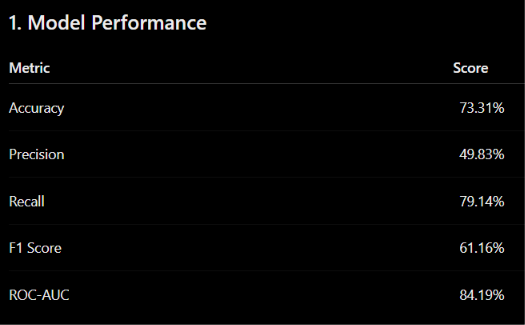

## Confusion Matrix

### Lets Visualize model's mistake

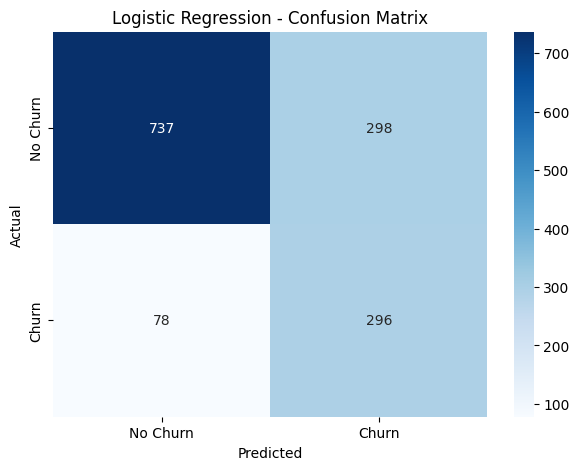

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No Churn', 'Churn'],
    yticklabels=['No Churn', 'Churn']
)

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Logistic Regression - Confusion Matrix')

plt.show()

In [14]:
print(cm)

[[737 298]
 [ 78 296]]


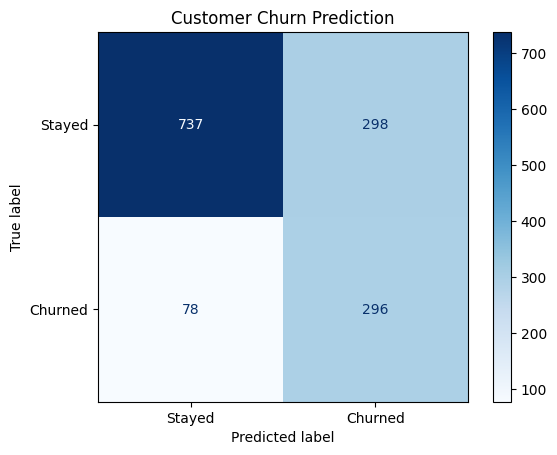

In [15]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Stayed', 'Churned']
)

disp.plot(cmap='Blues', values_format='d')
plt.title('Customer Churn Prediction')
plt.show()

Out of 374 customers who actually churned:
- our model identified 296.
- our model missed 78.

That's a recall of approximately 79.14%.

## New strategy
Reduce False Negatives (missed churners).

Maintain high Recall.

Avoid generating too many False Positives.

### Experiment with prediction threshold

In [16]:
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = [0.3, 0.35, 0.4, 0.45, 0.5,0.05]

for threshold in thresholds:

    predictions = (y_pred_proba >= threshold).astype(int)

    precision = precision_score(y_test, predictions)
    recall = recall_score(y_test, predictions)
    f1 = f1_score(y_test, predictions)

    print(f"\nThreshold: {threshold}")
    print(f"Precision: {precision:.3f}")
    print(f"Recall: {recall:.3f}")
    print(f"F1 Score: {f1:.3f}")


Threshold: 0.3
Precision: 0.427
Recall: 0.925
F1 Score: 0.584

Threshold: 0.35
Precision: 0.447
Recall: 0.904
F1 Score: 0.598

Threshold: 0.4
Precision: 0.472
Recall: 0.877
F1 Score: 0.614

Threshold: 0.45
Precision: 0.486
Recall: 0.832
F1 Score: 0.613

Threshold: 0.5
Precision: 0.498
Recall: 0.791
F1 Score: 0.612

Threshold: 0.05
Precision: 0.306
Recall: 0.995
F1 Score: 0.468


### Lets calculate the confusion matrix at threshold 0.35

[[617 418]
 [ 36 338]]


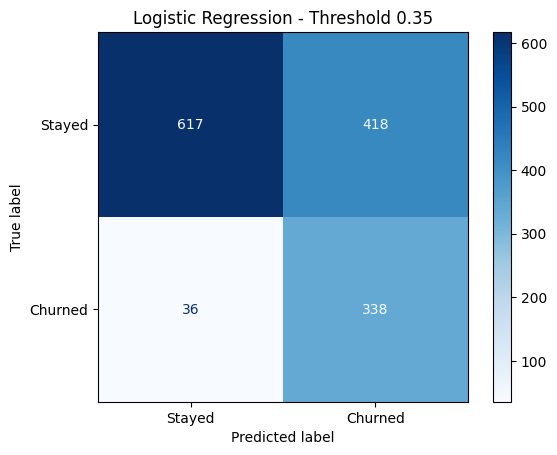

In [17]:
best_threshold = 0.35

y_pred_035 = (
    y_pred_proba >= best_threshold
).astype(int)

cm_035 = confusion_matrix(y_test, y_pred_035)

print(cm_035)

ConfusionMatrixDisplay(
    confusion_matrix=cm_035,
    display_labels=['Stayed', 'Churned']
).plot(cmap='Blues', values_format='d')

plt.title('Logistic Regression - Threshold 0.35')
plt.show()

### Save our baseline model

In [18]:
import joblib

model_path = os.path.join(
    project_path,
    'models',
    'logistic_regression_baseline.pkl'
)

os.makedirs(os.path.dirname(model_path), exist_ok=True)

joblib.dump(lr_model, model_path)

print("Baseline model saved successfully!")

Baseline model saved successfully!


## Random Forest Classifier 🌳

In [19]:
from sklearn.ensemble import RandomForestClassifier

In [20]:
rf_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=300,
        max_depth=None,
        min_samples_split=5,
        min_samples_leaf=2,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    ))
])

In [21]:
rf_model.fit(X_train, y_train)

print("Random Forest training completed!")

Random Forest training completed!


### GEnerate predictions

In [22]:
rf_pred = rf_model.predict(X_test)

rf_pred_proba = rf_model.predict_proba(X_test)[:, 1]

print("Random Forest predictions generated!")

Random Forest predictions generated!


### Calculate performance metrics

In [23]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

print("Accuracy:", accuracy_score(y_test, rf_pred))
print("Precision:", precision_score(y_test, rf_pred))
print("Recall:", recall_score(y_test, rf_pred))
print("F1 Score:", f1_score(y_test, rf_pred))
print("ROC-AUC:", roc_auc_score(y_test, rf_pred_proba))

print("\nClassification Report:")
print(classification_report(y_test, rf_pred))

Accuracy: 0.7757274662881476
Precision: 0.5703883495145631
Recall: 0.6283422459893048
F1 Score: 0.5979643765903307
ROC-AUC: 0.8334211682037769

Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.83      0.84      1035
           1       0.57      0.63      0.60       374

    accuracy                           0.78      1409
   macro avg       0.72      0.73      0.72      1409
weighted avg       0.78      0.78      0.78      1409



### Confusion Matrix

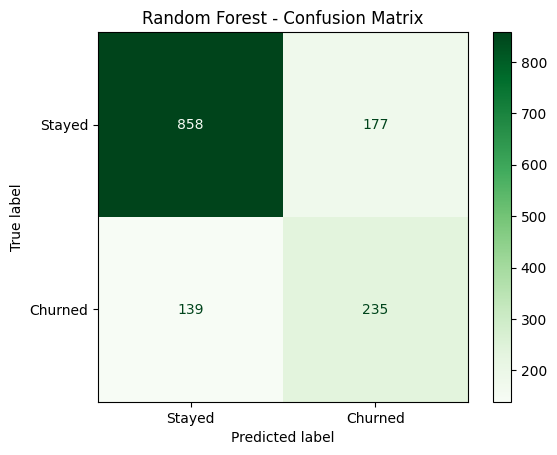

In [24]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    rf_pred,
    display_labels=['Stayed', 'Churned'],
    cmap='Greens',
    values_format='d'
)

plt.title('Random Forest - Confusion Matrix')
plt.show()

### Threshold Experiment

In [25]:
thresholds = [0.25, 0.30, 0.35, 0.40, 0.45, 0.50]

for threshold in thresholds:

    predictions = (
        rf_pred_proba >= threshold
    ).astype(int)

    precision = precision_score(y_test, predictions)
    recall = recall_score(y_test, predictions)
    f1 = f1_score(y_test, predictions)

    print(f"\nThreshold: {threshold}")
    print(f"Precision: {precision:.3f}")
    print(f"Recall: {recall:.3f}")
    print(f"F1 Score: {f1:.3f}")


Threshold: 0.25
Precision: 0.466
Recall: 0.880
F1 Score: 0.609

Threshold: 0.3
Precision: 0.492
Recall: 0.845
F1 Score: 0.622

Threshold: 0.35
Precision: 0.511
Recall: 0.794
F1 Score: 0.622

Threshold: 0.4
Precision: 0.532
Recall: 0.743
F1 Score: 0.620

Threshold: 0.45
Precision: 0.553
Recall: 0.698
F1 Score: 0.617

Threshold: 0.5
Precision: 0.570
Recall: 0.628
F1 Score: 0.598


Random Forest:
- Better precision.
- Better F1 score.
- Slightly lower recall.

Logistic Regression:
- Better at identifying customers who will churn.
- Better ROC-AUC.
- More suitable for our current priority of catching potential churners.

## LightGBM

In [26]:
!pip install lightgbm

In [27]:
from lightgbm import LGBMClassifier

In [28]:
lgbm_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LGBMClassifier(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=-1,
        num_leaves=31,
        class_weight='balanced',
        random_state=42,
        verbosity=-1
    ))
])

In [29]:
lgbm_model.fit(X_train, y_train)

print("LightGBM training completed!")

LightGBM training completed!


### GEnerate Predictions

In [30]:
lgbm_pred = lgbm_model.predict(X_test)

lgbm_pred_proba = lgbm_model.predict_proba(X_test)[:, 1]

print("LightGBM predictions generated!")

LightGBM predictions generated!


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


### Evaluate performance

In [31]:
print("Accuracy:", accuracy_score(y_test, lgbm_pred))
print("Precision:", precision_score(y_test, lgbm_pred))
print("Recall:", recall_score(y_test, lgbm_pred))
print("F1 Score:", f1_score(y_test, lgbm_pred))
print("ROC-AUC:", roc_auc_score(y_test, lgbm_pred_proba))

print("\nClassification Report:")
print(classification_report(y_test, lgbm_pred))

Accuracy: 0.7643718949609652
Precision: 0.5413385826771654
Recall: 0.7352941176470589
F1 Score: 0.6235827664399093
ROC-AUC: 0.8340437624325092

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.77      0.83      1035
           1       0.54      0.74      0.62       374

    accuracy                           0.76      1409
   macro avg       0.72      0.76      0.73      1409
weighted avg       0.80      0.76      0.77      1409



### Confusion Matrix

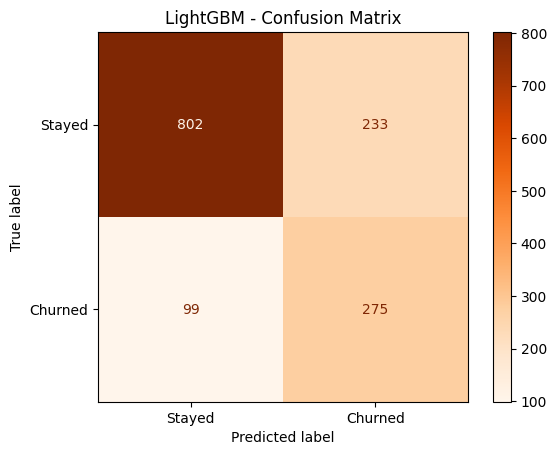

In [32]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    lgbm_pred,
    display_labels=['Stayed', 'Churned'],
    cmap='Oranges',
    values_format='d'
)

plt.title('LightGBM - Confusion Matrix')
plt.show()

### Threshold Experiment

In [33]:
thresholds = [0.25, 0.30, 0.35, 0.40, 0.45, 0.50]

for threshold in thresholds:

    predictions = (
        lgbm_pred_proba >= threshold
    ).astype(int)

    precision = precision_score(y_test, predictions)
    recall = recall_score(y_test, predictions)
    f1 = f1_score(y_test, predictions)

    print(f"\nThreshold: {threshold}")
    print(f"Precision: {precision:.3f}")
    print(f"Recall: {recall:.3f}")
    print(f"F1 Score: {f1:.3f}")


Threshold: 0.25
Precision: 0.449
Recall: 0.866
F1 Score: 0.591

Threshold: 0.3
Precision: 0.469
Recall: 0.845
F1 Score: 0.603

Threshold: 0.35
Precision: 0.491
Recall: 0.829
F1 Score: 0.616

Threshold: 0.4
Precision: 0.511
Recall: 0.802
F1 Score: 0.624

Threshold: 0.45
Precision: 0.524
Recall: 0.765
F1 Score: 0.622

Threshold: 0.5
Precision: 0.541
Recall: 0.735
F1 Score: 0.624


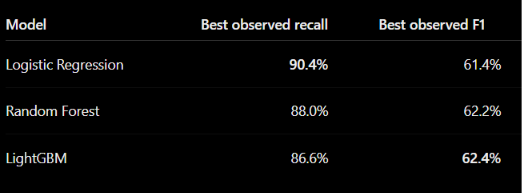

- Logistic Regression is currently strongest at identifying churners.

- Random Forest offers a better precision-recall balance than its default-threshold results suggest.

- LightGBM achieves the highest observed F1 score.

### Validation Data

In [34]:
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

print("Model training:", X_fit.shape)
print("Validation:", X_val.shape)
print("Final test:", X_test.shape)

Model training: (4507, 21)
Validation: (1127, 21)
Final test: (1409, 21)


### Retrain Logistic Regression

In [35]:
lr_model.fit(X_fit, y_fit)

print("Logistic Regression retrained!")

Logistic Regression retrained!


### Retrain Random Forest

In [36]:
rf_model.fit(X_fit, y_fit)

print("Random Forest retrained!")

Random Forest retrained!


### Retrain LightGBM

In [37]:
lgbm_model.fit(X_fit, y_fit)

print("LightGBM retrained!")

LightGBM retrained!


### Generate Validation Probabilities

In [38]:
lr_val_proba = lr_model.predict_proba(X_val)[:, 1]

rf_val_proba = rf_model.predict_proba(X_val)[:, 1]

lgbm_val_proba = lgbm_model.predict_proba(X_val)[:, 1]

print("Validation predictions generated!")

Validation predictions generated!


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


### Compare model performance

In [39]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

models = {
    'Logistic Regression': lr_val_proba,
    'Random Forest': rf_val_proba,
    'LightGBM': lgbm_val_proba
}

results = []

for name, probabilities in models.items():

    predictions = (probabilities >= 0.5).astype(int)

    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_val, predictions),
        'Precision': precision_score(y_val, predictions),
        'Recall': recall_score(y_val, predictions),
        'F1 Score': f1_score(y_val, predictions),
        'ROC-AUC': roc_auc_score(y_val, probabilities)
    })

results_df = pd.DataFrame(results)

results_df.round(3)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.753,0.523,0.783,0.627,0.848
1,Random Forest,0.790,0.597,0.635,0.616,0.838
2,LightGBM,0.773,0.558,0.696,0.619,0.836


### Compare threshold

In [40]:
thresholds = [0.25, 0.30, 0.35, 0.40, 0.45, 0.50]

threshold_results = []

for name, probabilities in models.items():

    for threshold in thresholds:

        predictions = (probabilities >= threshold).astype(int)

        threshold_results.append({
            'Model': name,
            'Threshold': threshold,
            'Precision': precision_score(y_val, predictions),
            'Recall': recall_score(y_val, predictions),
            'F1 Score': f1_score(y_val, predictions)
        })

threshold_df = pd.DataFrame(threshold_results)

threshold_df.round(3)

,Model,Threshold,Precision,Recall,F1 Score
0,Logistic Regression,0.25,0.402,0.926,0.561
1,Logistic Regression,0.30,0.417,0.913,0.573
2,Logistic Regression,0.35,0.434,0.876,0.581
3,Logistic Regression,0.40,0.466,0.860,0.604
4,Logistic Regression,0.45,0.484,0.816,0.608
5,Logistic Regression,0.50,0.523,0.783,0.627
6,Random Forest,0.25,0.453,0.863,0.594
7,Random Forest,0.30,0.483,0.823,0.609
8,Random Forest,0.35,0.511,0.783,0.618
9,Random Forest,0.40,0.540,0.749,0.627


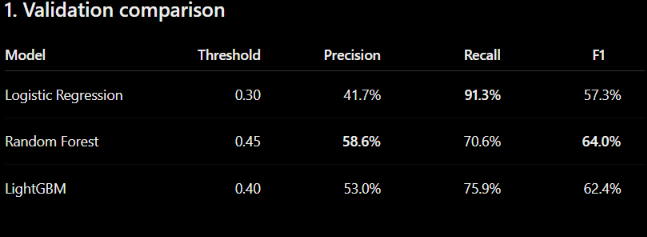

### Final Evaluation on untouched test data

In [41]:
final_test_proba = lr_model.predict_proba(X_test)[:, 1]

final_threshold = 0.30

final_predictions = (
    final_test_proba >= final_threshold
).astype(int)

In [42]:
print("FINAL LOGISTIC REGRESSION RESULTS")

print("Accuracy:",
      accuracy_score(y_test, final_predictions))

print("Precision:",
      precision_score(y_test, final_predictions))

print("Recall:",
      recall_score(y_test, final_predictions))

print("F1 Score:",
      f1_score(y_test, final_predictions))

print("ROC-AUC:",
      roc_auc_score(y_test, final_test_proba))

FINAL LOGISTIC REGRESSION RESULTS
Accuracy: 0.6479772888573456
Precision: 0.4250614250614251
Recall: 0.9251336898395722
F1 Score: 0.5824915824915825
ROC-AUC: 0.8431527551732155


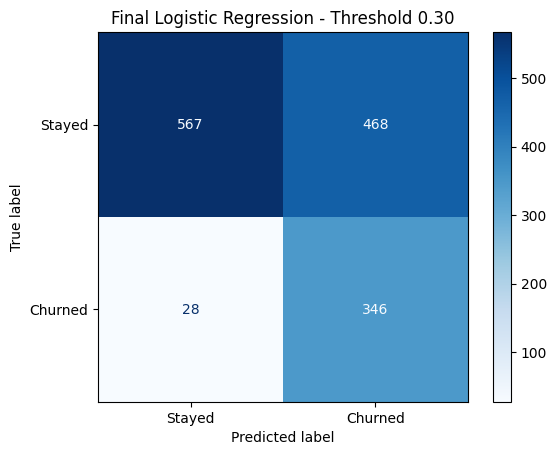

In [43]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    final_predictions,
    display_labels=['Stayed', 'Churned'],
    cmap='Blues',
    values_format='d'
)

plt.title('Final Logistic Regression - Threshold 0.30')
plt.show()

Out of 374 customers who actually churned:

- 346 were correctly identified.

- Only 28 were missed.

- 468 customers were incorrectly flagged as potential churners.

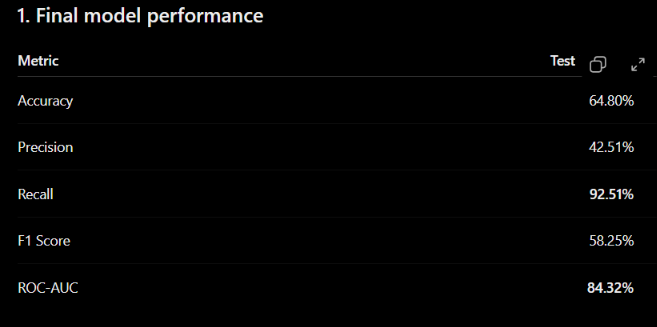

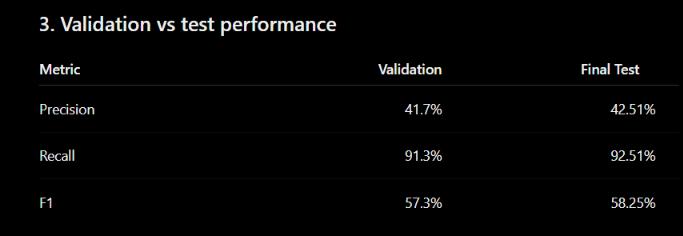

### Save this model

In [44]:
import joblib

final_model_path = os.path.join(
    project_path,
    'models',
    'final_logistic_regression.pkl'
)

joblib.dump(lr_model, final_model_path)

print("Final model saved successfully!")

Final model saved successfully!
